# L13 -  Entwurf rekursiver Filter

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l13.m).

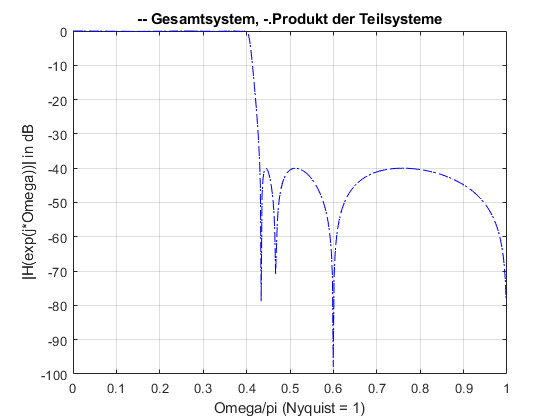

In [2]:
% ##############################################################################
% ##  Loesung:  Entwurf rekursiver Filter                                     ##
% ##############################################################################

fD = 1000;    %Durchlassfrequenz (Hz)
fS = 1400;    %Sperrfrequenz (Hz)
Rp = 0.5;     %Durchlassripple (dB)
Rs = 30;      %Sperrdaempfung (dB)
fA = 8000;    %Abtastfrequenz (Hz)
Wp = 2*fD/fA; %Umrechnung in normierte Grenzfrequenzen
Ws = 2*fS/fA;

for typ=1:4
    if typ == 1
        [n,Wn] = buttord(Wp,Ws,Rp,Rs);    %Butterworth
        [b,a]  = butter(n,Wn);
        FTyp = 'Butterworth';
    elseif typ == 2 
        [n,Wn] = cheb1ord(Wp,Ws,Rp,Rs);   %Tschebyscheff Typ I
        [b,a]  = cheby1(n,Rp,Wn);
        FTyp = 'Tschebyscheff Typ I';
    elseif typ == 3 
        [n,Wn] = cheb2ord(Wp,Ws,Rp,Rs);   %Tschebyscheff Typ II
        [b,a]  = cheby2(n,Rs,Wn);
        FTyp = 'Tschebyscheff Typ II';
    elseif typ == 4
        [n,Wn] = ellipord(Wp,Ws,Rp,Rs);   %Cauer
        [b,a]  = ellip(n,Rp,Rs,Wn);
        FTyp = 'Cauer';
    else
        error('Irgendwas stimmt nicht...');
    end

    [H,W]=freqz(b,a,512);
    
    % # grafische Ausgabe # %
    TitleString = sprintf('Filtertyp: %s  Ordnung: %d',  FTyp, n);
    
    % Frequenzgang
    figure; 
    plot(W/pi,abs(H)); 
    grid; 
    title(TitleString);
    xlabel('Omega/pi');
    ylabel('|H(exp(j*Omega))|'); 
    axis([0 1 0 1.2]);
    % Zeichnen des Toleranzschlauchs
    xline = [Wp Wp];
    yline = [0 10.^(-Rp/20)];           
    line(xline,yline,'linestyle','--');
    xline = [0 Ws]; 
    yline = [1 1];                      
    line(xline,yline,'linestyle','--');
    xline = [0 Wp]; 
    yline = [10.^(-Rp/20) 10.^(-Rp/20)];
    line(xline,yline,'linestyle','--');
    xline = [Ws Ws];
    yline = [10.^(-Rs/20) 1];
    line(xline,yline,'linestyle','--');
    xline = [Ws 1]; 
    yline = [10.^(-Rs/20) 10.^(-Rs/20)];
    line(xline,yline,'linestyle','--');
    
    % Pol- und Nullstellen in der z-Ebene
    figure; 
    zplane(b,a); 
    title(TitleString); 
    xlabel('Realteil');
    ylabel('Imaginaerteil');
end
% #####  EOF  #####
